# 구글 드라이브 연결

In [1]:
from google.colab import drive

drive.mount('/content/data')

Mounted at /content/data


# Load Data

In [2]:
import easydict

args = easydict.EasyDict()

args.default_path = "/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi"
# 학습할 이미지들
args.train_path = args.default_path + "/train"
# 학습할 이미지들을 증가!
args.train_data_augmentation_path = args.default_path + "/train_data_augmentation"

In [3]:
from pathlib import Path

train_path = Path(args.train_path)
train_path

PosixPath('/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi/train')

In [4]:
list(train_path.glob("*"))

[PosixPath('/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi/train/sushi'),
 PosixPath('/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi/train/steak'),
 PosixPath('/content/data/MyDrive/colab tutorial/data/pizza_steak_sushi/train/pizza')]

In [5]:
len(list(train_path.glob("*/*.jpg")))

225

In [6]:
train_data_augmentation_path = Path(args.train_data_augmentation_path)

# 만약 없다면, target 폴더 생성
for dir in ['sushi', 'steak', 'pizza']:
    target_path = train_data_augmentation_path / dir
    target_path.mkdir(parents=True, exist_ok=True)

# 연습

### 이미지 읽기

In [7]:
import random
from torchvision.io import read_image

random_img_path = random.choice(list(train_path.glob("*/*.jpg")))
img = read_image(random_img_path)
img.shape

torch.Size([3, 512, 512])

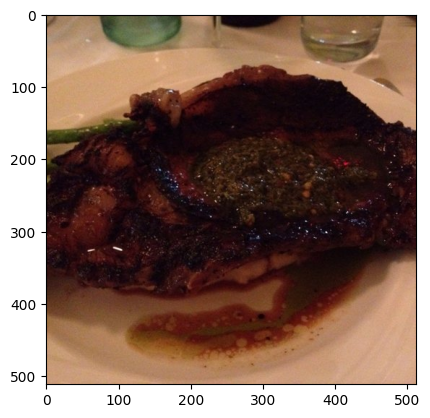

In [8]:
import numpy as np
import matplotlib.pyplot as plt

plt.imshow(img.permute(1,2,0).numpy())
plt.show()

### 이미지 전처리

In [9]:
from torchvision import transforms as T

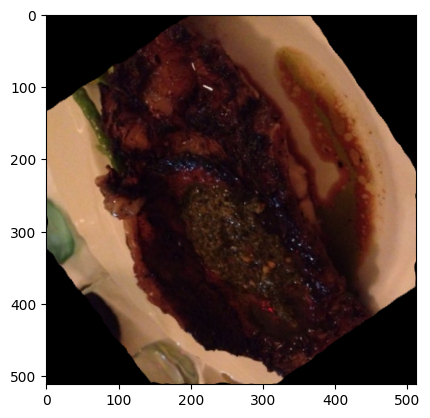

In [10]:
transformer = T.Compose([
    T.RandomPerspective(distortion_scale=0.1, p=1.0),
    T.RandomRotation(degrees=(0, 180)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.ElasticTransform(alpha=50.0)
])

trans_img = transformer(img)
plt.imshow(trans_img.permute(1,2,0).numpy())
plt.show()

### 이미지 저장하기

In [11]:
from torchvision.io import write_jpeg

write_jpeg(img, "./tmp_img.jpg")

# 데이터 증강하기

In [12]:
from tqdm.auto import tqdm

train_data_augmentation_path = Path(args.train_data_augmentation_path)
train_path = Path(args.train_path)

# 만약 없다면, target 폴더 생성
for dir in tqdm(['sushi', 'steak', 'pizza'], desc="타겟별 데이터 생성.."):

    # 저장해야할 폴더
    saved_dir = train_data_augmentation_path / dir
    # 타겟별로 이미지 조회
    for img_path in tqdm(
        list(train_path.glob(f"{dir}/*.jpg")), desc=f"{dir}의 이미지 생성..."):

        # 이미지 로드
        img = read_image(img_path)

        for i in range(4): # 하나의 이미지 4개로 증강
            trans_img = transformer(img) # 이미지 변환
            # 변환된 이미지 저장
            write_jpeg(trans_img, saved_dir / (str(i) + "_" + img_path.name))


타겟별 데이터 생성..:   0%|          | 0/3 [00:00<?, ?it/s]

sushi의 이미지 생성...:   0%|          | 0/72 [00:00<?, ?it/s]

steak의 이미지 생성...:   0%|          | 0/75 [00:00<?, ?it/s]

pizza의 이미지 생성...:   0%|          | 0/78 [00:00<?, ?it/s]

In [7]:
len(list(train_data_augmentation_path.glob("*/*.jpg")))

900

In [8]:
print(f"sushi: {len(list(train_data_augmentation_path.glob("sushi/*.jpg")))}")
print(f"steak: {len(list(train_data_augmentation_path.glob("steak/*.jpg")))}")
print(f"pizza: {len(list(train_data_augmentation_path.glob("pizza/*.jpg")))}")

sushi: 288
steak: 300
pizza: 312


In [11]:
import random

sampling_k = len(list(train_data_augmentation_path.glob("sushi/*.jpg")))
print(f"sushi: {len(list(train_data_augmentation_path.glob("sushi/*.jpg")))}")
print(f"steak: {len(random.sample(list(train_data_augmentation_path.glob("steak/*.jpg")), k=sampling_k))}")
print(f"pizza: {len(random.sample(list(train_data_augmentation_path.glob("pizza/*.jpg")), k=sampling_k))}")

sushi: 288
steak: 288
pizza: 288
